# 03 · Modelamiento: segunda entrega

Este notebook entrena y compara los modelos del curso para estimar, cuando llega una oferta de carga, la probabilidad de que el viaje termine pagado por debajo del costo de referencia del SICE-TAC.

Tres reglas que se respetan en todo el notebook. Primera: solo se lee `dataset_modelo_dic2025.csv`, que no tiene pago ni costo. Segunda: la clase que interesa detectar es la de viajes no rentables (que no cubren el costo de referencia); por eso precisión y sensibilidad se reportan para esa clase, y los odds ratios también se expresan como odds de no rentable. Tercera: el conjunto de prueba se separa al principio y no se vuelve a mirar hasta la entrega final.

Se comparan los modelos del curso: regresión logística, KNN, Naive Bayes y análisis discriminante (LDA y QDA).

El archivo de auditoría se lee una sola vez, en la sección 10, y solo para traer etiquetas alternativas que sirven para medir qué tan frágil es la etiqueta. Nunca para traer predictores.

## 1. Configuración y datos

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (average_precision_score, precision_score, recall_score, make_scorer,
                             roc_curve, roc_auc_score, confusion_matrix)
warnings.filterwarnings('ignore')

SEED = 42
N_FOLDS = 10
BASE = '/content' if os.path.exists('/content') else '.'
NUM = ['KILOMETROS', 'KILOGRAMOS']
CAT = ['CAPITULO', 'NATURALEZACARGA', 'DEPARTAMENTOORIGEN', 'DEPARTAMENTODESTINO']

df = pd.read_csv(f'{BASE}/dataset_modelo_dic2025.csv')
assert not {'VALORESPAGADOS', 'COSTO_REFERENCIA', 'RAZON_PAGO_COSTO'} & set(df.columns), 'Hay fuga en el archivo'
print(df.shape, '| rutas:', df['RUTA'].nunique())

(20868, 8) | rutas: 4146


## 2. Partición por ruta

Una misma ruta aparece varias veces (en promedio unos cinco viajes por ruta). Si partimos al azar, el modelo ve en entrenamiento la ruta Bogotá–Cali y luego lo evaluamos con otros viajes Bogotá–Cali: así parece mejor de lo que es con una ruta nueva. Por eso separamos 80 % y 20 % de modo que cada ruta quede completa de un solo lado, manteniendo la misma proporción de rentables en ambos.

In [2]:
sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_te = next(sgk.split(df, df['RENTABLE'], groups=df['RUTA']))
train, test = df.iloc[idx_tr].reset_index(drop=True), df.iloc[idx_te].reset_index(drop=True)
X_train, y_train, g_train = train[NUM + CAT], train['RENTABLE'], train['RUTA']
assert not set(train['RUTA']) & set(test['RUTA']), 'Hay rutas en entrenamiento y prueba a la vez'
print(f'Entrenamiento: {len(train):,} | Prueba: {len(test):,} ({len(test) / len(df):.1%})')
print(f"% rentables -> entrenamiento {y_train.mean():.3f} | prueba {test['RENTABLE'].mean():.3f}")
test.to_csv('conjunto_prueba_reservado.csv', index=False)   # se usa solo en la entrega final

Entrenamiento: 16,695 | Prueba: 4,173 (20.0%)
% rentables -> entrenamiento 0.677 | prueba 0.677


## 3. Exploración (solo con entrenamiento)

Miramos la forma de los datos para justificar el preprocesamiento. Kilómetros y kilos están sesgados a la derecha, por eso se transforman con logaritmo. Las categorías con pocos viajes se agrupan como “infrecuentes” para que el modelo no aprenda de diez casos.

In [3]:
display(X_train[NUM].describe().T.round(1))
print('Asimetría:', X_train[NUM].skew().round(2).to_dict())
print('Categorías:', X_train[CAT].nunique().to_dict())
print('Nulos:', int(X_train.isna().sum().sum()))
tmp = train.groupby('NATURALEZACARGA')['RENTABLE'].agg(['mean', 'count']).round(3)
tmp

,count,mean,std,min,25%,50%,75%,max
KILOMETROS,16695.0,402.8,325.0,3.0,126.0,375.0,568.0,1912.0
KILOGRAMOS,16695.0,4734.7,2847.3,5.0,2400.0,4500.0,7000.0,12000.0


Asimetría: {'KILOMETROS': 0.84, 'KILOGRAMOS': 0.37}
Categorías: {'CAPITULO': 98, 'NATURALEZACARGA': 5, 'DEPARTAMENTOORIGEN': 29, 'DEPARTAMENTODESTINO': 29}
Nulos: 0


,mean,count
NATURALEZACARGA,,
Carga Normal,0.679,15925
Carga Peligrosa,0.772,316
Desechos Peligrosos,0.579,19
Refrigerada,0.498,418
Semovientes,0.941,17


## 4. El flujo sin fuga

Todo lo que aprende de los datos va dentro del `Pipeline`: las medianas para imputar, la media y la desviación para escalar, y la lista de categorías del one-hot. En cada fold de la validación cruzada se recalcula solo con la parte de entrenamiento de ese fold. Así ningún dato de validación se cuela en la preparación.

El orden es imputar, aplicar logaritmo, escalar y codificar. Imputar va primero porque el logaritmo no acepta vacíos; escalar va después del logaritmo porque lo que queremos centrar es la variable ya transformada.

In [4]:
def hacer_pipe(clf, num_transform=None):
    num = num_transform or Pipeline([('imp', SimpleImputer(strategy='median')),
                                     ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                                     ('sc', StandardScaler())])
    cat = Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='SIN_DATO')),
                    ('oh', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False))])
    return Pipeline([('pre', ColumnTransformer([('num', num, NUM), ('cat', cat, CAT)])), ('clf', clf)])

def cv_grupos(seed=SEED, k=N_FOLDS):
    return StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)

def pr_auc_no_rentable(est, X_, y_):
    p0 = est.predict_proba(X_)[:, list(est.classes_).index(0)]
    return average_precision_score((np.asarray(y_) == 0).astype(int), p0)

SCORING = {'auc': 'roc_auc',
           'precision_no_rent': make_scorer(precision_score, pos_label=0, zero_division=0),
           'recall_no_rent': make_scorer(recall_score, pos_label=0, zero_division=0),
           'pr_auc_no_rent': pr_auc_no_rentable}

## 5. Línea base

Un clasificador que siempre dice “rentable”. Acierta en dos de cada tres viajes sin aprender nada y nunca detecta un viaje no rentable. Es el piso que cualquier modelo tiene que superar, y es la razón por la que el accuracy no sirve como métrica principal. Su precisión para la clase no rentable no está definida, porque nunca marca un viaje como no rentable; scikit-learn la reporta como cero por convención.

In [5]:
resultados = {}
resultados['Línea base'] = cross_validate(hacer_pipe(DummyClassifier(strategy='most_frequent')), X_train, y_train,
                                          cv=cv_grupos(), groups=g_train, scoring=SCORING)
print('Accuracy de la línea base:', round(1 - (y_train == 0).mean(), 3))
{k[5:]: round(v.mean(), 3) for k, v in resultados['Línea base'].items() if k.startswith('test_')}

Accuracy de la línea base: 0.677


{'auc': np.float64(0.5),
 'precision_no_rent': np.float64(0.0),
 'recall_no_rent': np.float64(0.0),
 'pr_auc_no_rent': np.float64(0.323)}

## 6. Ajuste de hiperparámetros

Cada modelo prueba unas pocas combinaciones con validación cruzada de 10 folds agrupados por ruta, y se queda con la de mayor AUC. Naive Bayes, LDA y QDA suponen variables continuas con forma de campana, y aquí hay muchas columnas de ceros y unos; eso les juega en contra y hay que decirlo al comparar.

In [6]:
MODELOS = {
    'Regresión logística': (LogisticRegression(max_iter=3000), {'clf__C': [0.01, 0.1, 1, 10]}),
    'KNN': (KNeighborsClassifier(), {'clf__n_neighbors': [15, 31, 61]}),
    'Naive Bayes': (GaussianNB(), {'clf__var_smoothing': [1e-9, 1e-6, 1e-3]}),
    'LDA': (LinearDiscriminantAnalysis(solver='lsqr'), {'clf__shrinkage': [None, 'auto']}),
    'QDA': (QuadraticDiscriminantAnalysis(), {'clf__reg_param': [0.1, 0.5, 0.9]}),
}
mejores, ajuste = {}, []
for nombre, (clf, grilla) in MODELOS.items():
    gs = GridSearchCV(hacer_pipe(clf), grilla, scoring='roc_auc', cv=cv_grupos(), refit=True)
    gs.fit(X_train, y_train, groups=g_train)
    mejores[nombre] = gs.best_estimator_
    ajuste.append({'Modelo': nombre, 'Mejores parámetros': gs.best_params_, 'AUC en la búsqueda': round(gs.best_score_, 4)})
    print(nombre, gs.best_params_, round(gs.best_score_, 4))
pd.DataFrame(ajuste).to_csv('tabla_ajuste.csv', index=False)

Regresión logística {'clf__C': 0.1} 0.7737


KNN {'clf__n_neighbors': 61} 0.7875


Naive Bayes {'clf__var_smoothing': 0.001} 0.6058


LDA {'clf__shrinkage': None} 0.7703


QDA {'clf__reg_param': 0.1} 0.7625


## 7. Comparación con variabilidad

Cada modelo ya ajustado se vuelve a evaluar con otra partición en 10 folds (otra semilla), para no medirlo con los mismos cortes con los que se eligió. Se comparan con dos métricas que no dependen de ningún umbral: el AUC y el PR-AUC de la clase no rentable, con su media y desviación entre folds.

Precisión y sensibilidad sí dependen del umbral, y cada modelo produce probabilidades en escalas distintas. Compararlos a todos con 0,5 favorece o castiga a cada uno según su calibración. Por eso, para cada modelo se busca su propio umbral de Youden con probabilidades fuera de muestra, y la precisión y la sensibilidad se reportan en ese punto. En la misma pasada se repite el AUC con folds al azar, sin agrupar, para ver cuánto ayudaba “recordar” rutas.

In [7]:
SC2 = {'auc': 'roc_auc', 'pr_auc_no_rent': pr_auc_no_rentable}
candidatos = {'Línea base': hacer_pipe(DummyClassifier(strategy='most_frequent')), **mejores}
filas, oof = [], {}
for nombre, est in candidatos.items():
    r = cross_validate(est, X_train, y_train, cv=cv_grupos(SEED + 1), groups=g_train, scoring=SC2)
    r_azar = cross_validate(est, X_train, y_train, cv=StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED + 1), scoring='roc_auc')
    resultados[nombre] = r
    fila = {'Modelo': nombre, 'AUC': r['test_auc'].mean(), 'AUC_sd': r['test_auc'].std(),
            'PR_AUC_no_rent': r['test_pr_auc_no_rent'].mean(), 'PR_AUC_sd': r['test_pr_auc_no_rent'].std(),
            'AUC_folds_al_azar': r_azar['test_score'].mean()}
    if nombre != 'Línea base':
        p = cross_val_predict(est, X_train, y_train, cv=cv_grupos(SEED + 1), groups=g_train, method='predict_proba')[:, 0]
        oof[nombre] = p
        yn = (y_train.values == 0).astype(int)
        f_, t_, u_ = roc_curve(yn, p); k = np.argmax(t_ - f_)
        pr = (p >= u_[k]).astype(int)
        fila.update({'Umbral_Youden': u_[k], 'Sensibilidad_no_rent': recall_score(yn, pr), 'Precision_no_rent': precision_score(yn, pr)})
    else:
        fila.update({'Umbral_Youden': np.nan, 'Sensibilidad_no_rent': 0.0, 'Precision_no_rent': np.nan})
    filas.append(fila)
comp = pd.DataFrame(filas)
comp.to_csv('tabla_comparacion.csv', index=False)
vista = pd.DataFrame({
    'AUC': comp['AUC'].map('{:.3f}'.format) + ' ± ' + comp['AUC_sd'].map('{:.3f}'.format),
    'PR-AUC no rentable': comp['PR_AUC_no_rent'].map('{:.3f}'.format) + ' ± ' + comp['PR_AUC_sd'].map('{:.3f}'.format),
    'Umbral Youden': comp['Umbral_Youden'].map(lambda v: '—' if pd.isna(v) else f'{v:.2f}'),
    'Sensibilidad (Youden)': comp['Sensibilidad_no_rent'].map('{:.3f}'.format),
    'Precisión (Youden)': comp['Precision_no_rent'].map(lambda v: 'no definida' if pd.isna(v) else f'{v:.3f}'),
    'AUC folds al azar': comp['AUC_folds_al_azar'].map('{:.3f}'.format)}).set_axis(comp['Modelo'])
vista

,AUC,PR-AUC no rentable,Umbral Youden,Sensibilidad (Youden),Precisión (Youden),AUC folds al azar
Modelo,,,,,,
Línea base,0.500 ± 0.000,0.323 ± 0.000,—,0.000,no definida,0.500
Regresión logística,0.774 ± 0.021,0.599 ± 0.034,0.31,0.747,0.526,0.776
KNN,0.787 ± 0.018,0.627 ± 0.028,0.36,0.703,0.563,0.796
Naive Bayes,0.605 ± 0.025,0.407 ± 0.019,0.93,0.486,0.426,0.616
LDA,0.771 ± 0.021,0.592 ± 0.035,0.30,0.731,0.523,0.773
QDA,0.763 ± 0.026,0.589 ± 0.039,0.38,0.730,0.525,0.766


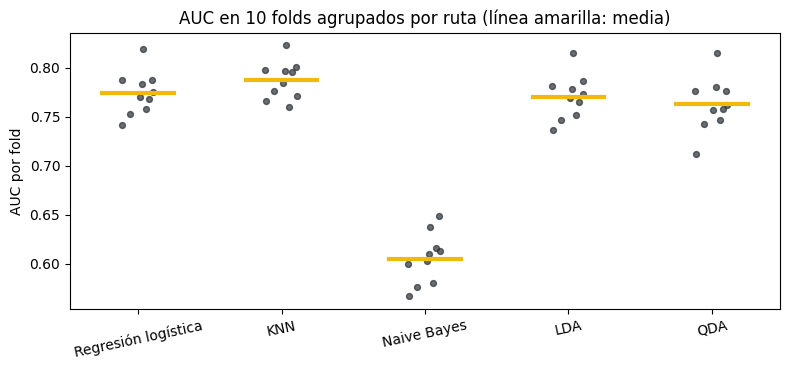

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
nombres = list(mejores)
for i, n in enumerate(nombres):
    a = resultados[n]['test_auc']
    ax.scatter(np.full(len(a), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(a)), a, s=18, alpha=0.7, color='#2A3036')
    ax.plot([i - 0.25, i + 0.25], [a.mean()] * 2, color='#F0B90B', lw=3)
ax.set_xticks(range(len(nombres))); ax.set_xticklabels(nombres, rotation=12)
ax.set_ylabel('AUC por fold'); ax.set_title('AUC en 10 folds agrupados por ruta (línea amarilla: media)')
plt.tight_layout(); plt.savefig('fig_auc_modelos.png', dpi=200); plt.show()

Los hiperparámetros se eligieron y se evaluaron con el mismo conjunto de entrenamiento (con otra semilla), así que la estimación puede ser un poco optimista. Para medir cuánto, se repite la logística con validación anidada: el ajuste del parámetro C se hace dentro de cada fold externo, sin ver ese fold.

In [9]:
externo = cv_grupos(SEED + 3, k=5)
aucs_anidado = []
for tr_i, va_i in externo.split(X_train, y_train, groups=g_train):
    gs = GridSearchCV(hacer_pipe(LogisticRegression(max_iter=3000)), MODELOS['Regresión logística'][1],
                      scoring='roc_auc', cv=cv_grupos(SEED + 4, k=5))
    gs.fit(X_train.iloc[tr_i], y_train.iloc[tr_i], groups=g_train.iloc[tr_i])
    aucs_anidado.append(roc_auc_score(y_train.iloc[va_i], gs.predict_proba(X_train.iloc[va_i])[:, 1]))
anidado = {'AUC_anidado': np.mean(aucs_anidado), 'AUC_anidado_sd': np.std(aucs_anidado)}
pd.DataFrame([anidado]).to_csv('tabla_validacion_anidada.csv', index=False)
print(f"AUC con validación anidada: {anidado['AUC_anidado']:.3f} ± {anidado['AUC_anidado_sd']:.3f}")

AUC con validación anidada: 0.774 ± 0.012


## 8. Qué está aprendiendo el modelo

Antes de interpretar coeficientes conviene saber qué variables cargan el resultado. Entrenamos la logística con subconjuntos de variables y comparamos el AUC. Si la distancia sola explica casi todo, hay que decirlo: es un hallazgo y también una advertencia, porque el costo del SICE-TAC depende sobre todo de la distancia.

In [10]:
abl = []
for etiqueta, cols_num, cols_cat in [('Solo kilómetros', ['KILOMETROS'], []), ('Kilómetros y kilos', NUM, []),
                                     ('Solo categóricas', [], CAT), ('Modelo completo', NUM, CAT)]:
    partes = []
    if cols_num: partes.append(('num', Pipeline([('log', FunctionTransformer(np.log1p)), ('sc', StandardScaler())]), cols_num))
    if cols_cat: partes.append(('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='SIN_DATO')),
                                                ('oh', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))]), cols_cat))
    p = Pipeline([('pre', ColumnTransformer(partes)), ('clf', LogisticRegression(max_iter=3000, C=mejores['Regresión logística'].get_params()['clf__C']))])
    r = cross_validate(p, X_train, y_train, cv=cv_grupos(SEED + 1), groups=g_train, scoring='roc_auc')
    abl.append({'Variables': etiqueta, 'AUC': r['test_score'].mean(), 'sd': r['test_score'].std()})
abl = pd.DataFrame(abl); abl.to_csv('tabla_ablacion.csv', index=False); abl.round(3)

,Variables,AUC,sd
0,Solo kilómetros,0.674,0.041
1,Kilómetros y kilos,0.745,0.021
2,Solo categóricas,0.630,0.040
3,Modelo completo,0.774,0.021


## 9. Umbral, errores y odds ratios

Sobre el umbral. El modelo entrega una probabilidad de que el viaje sea no rentable; hay que decidir desde qué valor se alerta. Seguimos al artículo y usamos el índice de Youden sobre probabilidades fuera de muestra. Youden pesa igual los dos errores, así que al lado mostramos qué pasaría si aceptar un viaje no rentable le costara al transportador tres veces más que rechazar uno rentable. Ese 3 a 1 es un ejemplo, no un dato.

In [11]:
mejor = 'Regresión logística'
p0 = oof[mejor]   # las mismas probabilidades fuera de muestra de la sección 7
y_neg = (y_train.values == 0).astype(int)
fpr, tpr, thr = roc_curve(y_neg, p0)
u_youden = thr[np.argmax(tpr - fpr)]
costos = [(t, 3 * ((p0 < t) & (y_neg == 1)).sum() + ((p0 >= t) & (y_neg == 0)).sum()) for t in np.linspace(0.05, 0.95, 181)]
u_costo = min(costos, key=lambda x: x[1])[0]
def resumen(u, nombre):
    pr = (p0 >= u).astype(int)
    return {'Criterio': nombre, 'Umbral': round(u, 3), 'Sensibilidad no rentable': recall_score(y_neg, pr),
            'Precisión no rentable': precision_score(y_neg, pr), 'Ofertas marcadas': pr.mean()}
umb = pd.DataFrame([resumen(0.5, 'Por defecto 0,5'), resumen(u_youden, 'Youden (artículo)'), resumen(u_costo, 'Costo 3 a 1')])
umb.to_csv('tabla_umbrales.csv', index=False)
print('AUC fuera de muestra de la logística:', round(roc_auc_score(y_neg, p0), 3))
umb.round(3)

AUC fuera de muestra de la logística: 0.774


,Criterio,Umbral,Sensibilidad no rentable,Precisión no rentable,Ofertas marcadas
0,"Por defecto 0,5",0.500,0.403,0.655,0.199
1,Youden (artículo),0.311,0.747,0.526,0.458
2,Costo 3 a 1,0.250,0.840,0.473,0.574


In [12]:
cm = confusion_matrix(y_neg, (p0 >= u_youden).astype(int))
cm_df = pd.DataFrame(cm, index=['Real: rentable', 'Real: no rentable'], columns=['Modelo: rentable', 'Modelo: no rentable'])
cm_df.to_csv('matriz_confusion_youden.csv'); cm_df

,Modelo: rentable,Modelo: no rentable
Real: rentable,7675,3625
Real: no rentable,1367,4028


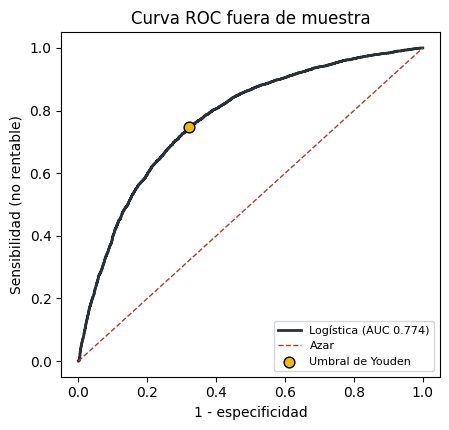

In [13]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot(fpr, tpr, color='#2A3036', lw=2, label=f'Logística (AUC {roc_auc_score(y_neg, p0):.3f})')
ax.plot([0, 1], [0, 1], ls='--', color='#B23A2E', lw=1, label='Azar')
j = np.argmax(tpr - fpr); ax.scatter(fpr[j], tpr[j], color='#F0B90B', edgecolor='k', zorder=3, s=60, label='Umbral de Youden')
ax.set_xlabel('1 - especificidad'); ax.set_ylabel('Sensibilidad (no rentable)'); ax.legend(fontsize=8, loc='lower right')
ax.set_title('Curva ROC fuera de muestra')
plt.tight_layout(); plt.savefig('fig_roc.png', dpi=200); plt.show()

Sobre los odds ratios. Para leer el efecto de cada variable se estima un modelo de interpretación con statsmodels, como hace el artículo. Usa exactamente las mismas variables que el modelo de predicción, con dos diferencias que hay que tener presentes: no tiene regularización, y las categorías con menos de 50 viajes de entrenamiento se juntan en “OTRO” (lo mismo que hace el one-hot del pipeline con las infrecuentes). Kilómetros y kilos entran en logaritmo base 2, así que el efecto se lee “si la distancia se duplica”. Cada categoría se compara con una referencia explícita: carga normal, el capítulo más frecuente y Bogotá como origen y destino. Los errores estándar se agrupan por ruta.

Para ser coherentes con la clase positiva de las métricas, el modelo estima las odds de que el viaje sea no rentable. Un odds ratio mayor que 1 significa más riesgo de no cubrir el costo. Son odds, no probabilidad.

In [14]:
d = train.copy()
d['NO_RENTABLE'] = 1 - d['RENTABLE']
d['log2_km'], d['log2_kg'] = np.log2(d['KILOMETROS']), np.log2(d['KILOGRAMOS'])
for col in CAT:
    frec = d[col].value_counts()
    d[col + '_G'] = d[col].where(d[col].isin(frec[frec >= 50].index), 'OTRO')
cap_ref = d['CAPITULO_G'].value_counts().index[0]
formula = ("NO_RENTABLE ~ log2_km + log2_kg"
           " + C(NATURALEZACARGA_G, Treatment('Carga Normal'))"
           f" + C(CAPITULO_G, Treatment('{cap_ref}'))"
           " + C(DEPARTAMENTOORIGEN_G, Treatment('BOGOTA D. C.'))"
           " + C(DEPARTAMENTODESTINO_G, Treatment('BOGOTA D. C.'))")
logit = smf.logit(formula, d).fit(disp=0, maxiter=200, cov_type='cluster', cov_kwds={'groups': pd.factorize(d['RUTA'])[0]})
print('Convergió:', logit.mle_retvals['converged'], '| parámetros:', len(logit.params), '| capítulo de referencia:', cap_ref)
ic = np.exp(logit.conf_int())
tabla_or = pd.DataFrame({'OR_no_rentable': np.exp(logit.params), 'IC 2,5 %': ic[0], 'IC 97,5 %': ic[1], 'p': logit.pvalues})
tabla_or.index = (tabla_or.index.str.replace(r"C\((\w+)_G, Treatment\('.*?'\)\)\[T\.", r'\1: ', regex=True).str.replace(']', ''))
tabla_or.to_csv('tabla_odds_ratios.csv')
print('Pseudo R2 de McFadden:', round(logit.prsquared, 3))
tabla_or.loc[[i for i in tabla_or.index if not i.startswith('CAPITULO')]].round(3)

Convergió: True | parámetros: 115 | capítulo de referencia: CAP_98
Pseudo R2 de McFadden: 0.172


,OR_no_rentable,"IC 2,5 %","IC 97,5 %",p
Intercept,8.972,4.821,16.696,0.000
NATURALEZACARGA: Carga Peligrosa,0.702,0.512,0.963,0.028
NATURALEZACARGA: OTRO,0.935,0.403,2.172,0.876
NATURALEZACARGA: Refrigerada,3.544,2.592,4.845,0.000
DEPARTAMENTOORIGEN: ANTIOQUIA,1.024,0.820,1.278,0.836
DEPARTAMENTOORIGEN: ATLANTICO,1.204,0.923,1.569,0.171
DEPARTAMENTOORIGEN: BOLIVAR,1.111,0.851,1.449,0.439
DEPARTAMENTOORIGEN: BOYACA,0.973,0.584,1.622,0.917
DEPARTAMENTOORIGEN: CALDAS,0.693,0.399,1.202,0.191
DEPARTAMENTOORIGEN: CASANARE,0.708,0.449,1.115,0.136


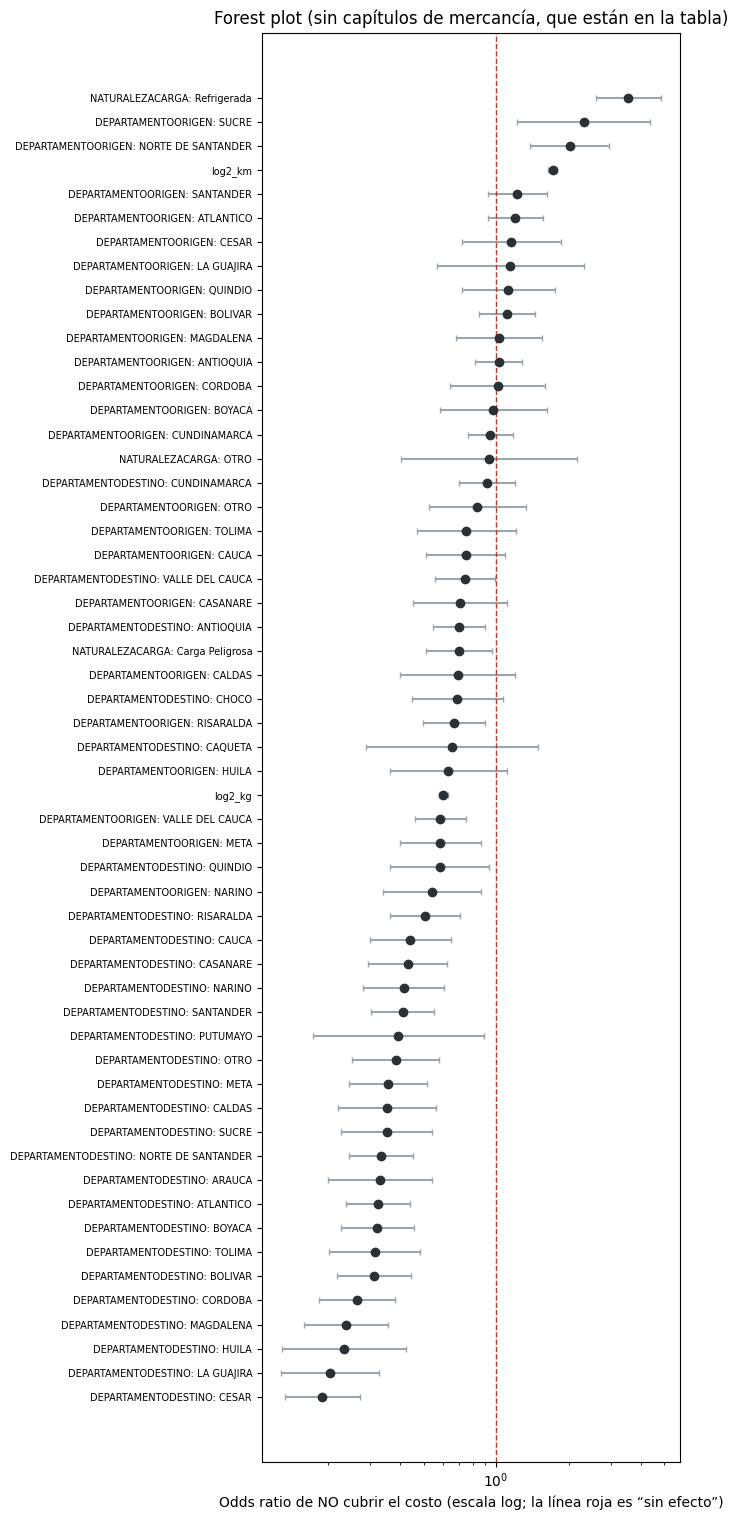

In [15]:
t = tabla_or.loc[[i for i in tabla_or.index if i != 'Intercept' and not i.startswith('CAPITULO')]].sort_values('OR_no_rentable')
fig, ax = plt.subplots(figsize=(7, 0.26 * len(t) + 1))
y = np.arange(len(t))
ax.errorbar(t['OR_no_rentable'], y, xerr=[t['OR_no_rentable'] - t['IC 2,5 %'], t['IC 97,5 %'] - t['OR_no_rentable']],
            fmt='o', color='#2A3036', ecolor='#9AA5AD', capsize=2)
ax.axvline(1, color='#B23A2E', ls='--', lw=1)
ax.set_yticks(y); ax.set_yticklabels(t.index, fontsize=7); ax.set_xscale('log')
ax.set_xlabel('Odds ratio de NO cubrir el costo (escala log; la línea roja es “sin efecto”)')
ax.set_title('Forest plot (sin capítulos de mercancía, que están en la tabla)')
plt.tight_layout(); plt.savefig('fig_forest_or.png', dpi=200); plt.show()

Sobre los supuestos. El artículo revisa que la variable sea binaria, que los predictores no estén correlacionados, que el logit sea lineal en las variables numéricas y que el modelo ajuste bien (Hosmer-Lemeshow). Se hace lo mismo, con tres precisiones. La calibración y Hosmer-Lemeshow se calculan con las probabilidades fuera de muestra del modelo que se evalúa (la logística de scikit-learn), no con el de interpretación. La prueba de Box-Tidwell es dentro de muestra y sin errores agrupados, así que con 16.000 viajes rechaza incluso desviaciones pequeñas; la evidencia principal sobre linealidad es el gráfico por deciles. Y la independencia no se cumple del todo porque las rutas se repiten; por eso se agrupa por ruta la validación y los errores estándar.

In [16]:
Z = np.log(train[NUM]); Z = (Z - Z.mean()) / Z.std(); Z.insert(0, 'const', 1.0)
vif = {c: round(variance_inflation_factor(Z.values, i), 3) for i, c in enumerate(Z.columns) if c != 'const'}
print('VIF:', vif)

d['bt_km'] = np.log(d['KILOMETROS']) * np.log(np.log(d['KILOMETROS']).clip(lower=1e-6))
d['bt_kg'] = np.log(d['KILOGRAMOS']) * np.log(np.log(d['KILOGRAMOS']).clip(lower=1e-6))
d1 = d[d['KILOGRAMOS'] > 1]   # ln(ln(1)) no está definido
bt = smf.logit('RENTABLE ~ np.log(KILOMETROS) + np.log(KILOGRAMOS) + bt_km + bt_kg', d1).fit(disp=0)
print('Box-Tidwell sobre el logaritmo (p, dentro de muestra):', bt.pvalues[['bt_km', 'bt_kg']].round(4).to_dict())

p_rent = 1 - p0   # probabilidad fuera de muestra de ser rentable, modelo evaluado
dec = pd.qcut(p_rent, 10, duplicates='drop')
g = pd.DataFrame({'y': y_train.values, 'p': p_rent}).groupby(dec, observed=True).agg(obs=('y', 'sum'), esp=('p', 'sum'), n=('y', 'size'))
hl = (((g['obs'] - g['esp']) ** 2) / (g['esp'] * (1 - g['esp'] / g['n']))).sum()
p_hl = 1 - stats.chi2.cdf(hl, len(g) - 2)
calib = pd.DataFrame({'Observado': g['obs'] / g['n'], 'Predicho': g['esp'] / g['n']})
dif = (calib.Observado - calib.Predicho).abs().max()
print(f'Hosmer-Lemeshow fuera de muestra: {hl:.1f}, p = {p_hl:.4f} | diferencia máxima por decil: {dif:.3f}')
pd.DataFrame({'VIF_km': [vif['KILOMETROS']], 'VIF_kg': [vif['KILOGRAMOS']], 'BT_p_km': [bt.pvalues['bt_km']], 'BT_p_kg': [bt.pvalues['bt_kg']],
              'HL': [hl], 'HL_p': [p_hl], 'calib_max_diff': [dif]}).to_csv('tabla_supuestos.csv', index=False)
calib.round(3)

VIF: {'KILOMETROS': np.float64(1.019), 'KILOGRAMOS': np.float64(1.019)}
Box-Tidwell sobre el logaritmo (p, dentro de muestra): {'bt_km': 0.0, 'bt_kg': 0.0}
Hosmer-Lemeshow fuera de muestra: 107.7, p = 0.0000 | diferencia máxima por decil: 0.059


,Observado,Predicho
"(0.0035700000000000003, 0.376]",0.306,0.266
"(0.376, 0.502]",0.385,0.444
"(0.502, 0.589]",0.491,0.547
"(0.589, 0.655]",0.609,0.623
"(0.655, 0.71]",0.683,0.684
"(0.71, 0.764]",0.757,0.737
"(0.764, 0.815]",0.842,0.789
"(0.815, 0.867]",0.868,0.842
"(0.867, 0.916]",0.896,0.892
"(0.916, 0.99]",0.932,0.947


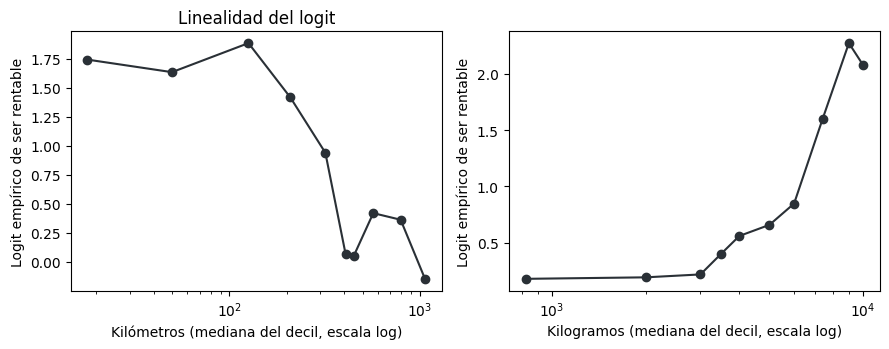

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, v, lab in [(axes[0], 'KILOMETROS', 'Kilómetros'), (axes[1], 'KILOGRAMOS', 'Kilogramos')]:
    q = pd.qcut(np.log(d[v]), 10, duplicates='drop')
    e = d.groupby(q, observed=True)['RENTABLE'].agg(['sum', 'size'])
    logit_emp = np.log((e['sum'] + 0.5) / (e['size'] - e['sum'] + 0.5))
    x = d.groupby(q, observed=True)[v].median()
    ax.plot(x, logit_emp, 'o-', color='#2A3036'); ax.set_xscale('log')
    ax.set_xlabel(f'{lab} (mediana del decil, escala log)'); ax.set_ylabel('Logit empírico de ser rentable')
axes[0].set_title('Linealidad del logit'); plt.tight_layout(); plt.savefig('fig_linealidad.png', dpi=200); plt.show()

In [18]:
spl = Pipeline([('log', FunctionTransformer(np.log1p)), ('sp', SplineTransformer(n_knots=4, degree=3)), ('sc', StandardScaler())])
r_spl = cross_validate(hacer_pipe(LogisticRegression(max_iter=3000, C=mejores[mejor].get_params()['clf__C']), num_transform=spl),
                       X_train, y_train, cv=cv_grupos(SEED + 1), groups=g_train, scoring='roc_auc')
pd.DataFrame([{'AUC_log': resultados[mejor]['test_auc'].mean(), 'AUC_splines': r_spl['test_score'].mean(),
               'AUC_splines_sd': r_spl['test_score'].std()}]).to_csv('tabla_splines.csv', index=False)
print(f"AUC logística con logaritmo: {resultados[mejor]['test_auc'].mean():.3f} | con splines: {r_spl['test_score'].mean():.3f}")

AUC logística con logaritmo: 0.774 | con splines: 0.796


## 10. Qué tan frágil es la etiqueta

Volvemos a entrenar la logística con etiquetas construidas con otros supuestos (carrocería más cara y la fórmula de la primera entrega) y medimos el AUC. También la entrenamos sin los viajes cuyo pago queda a menos de 10 % del costo, que son los que más dependen de los supuestos. Del archivo de auditoría solo se toman etiquetas; los predictores siguen siendo los mismos.

In [19]:
aud = pd.read_csv(f'{BASE}/dataset_auditoria_dic2025.csv')
assert len(aud) == len(df) and (aud['RENTABLE'].values == df['RENTABLE'].values).all(), 'Auditoría y modelo no están alineados'
aud_tr = aud.iloc[idx_tr].reset_index(drop=True)
filas = []
for nombre, y_alt, mask in [('Principal', y_train, None),
                            ('Carrocería más cara', aud_tr['RENTABLE_CARROCERIA_CARA'], None),
                            ('Fórmula de la primera entrega', aud_tr['RENTABLE_FORMULA_ANTERIOR'], None),
                            ('Sin viajes a ±10 % del costo', y_train, ~aud_tr['RAZON_PAGO_COSTO'].between(0.9, 1.1))]:
    Xa, ya, ga = (X_train, y_alt, g_train) if mask is None else (X_train[mask.values], y_alt[mask.values], g_train[mask.values])
    r = cross_validate(mejores[mejor], Xa, ya, cv=cv_grupos(SEED + 1), groups=ga, scoring='roc_auc')
    filas.append({'Etiqueta': nombre, 'Viajes': len(ya), '% rentables': ya.mean(), 'AUC': r['test_score'].mean(), 'sd': r['test_score'].std()})
sens_m = pd.DataFrame(filas); sens_m.to_csv('tabla_sensibilidad_modelo.csv', index=False); sens_m.round(3)

,Etiqueta,Viajes,% rentables,AUC,sd
0,Principal,16695,0.677,0.774,0.021
1,Carrocería más cara,16695,0.595,0.773,0.016
2,Fórmula de la primera entrega,16695,0.571,0.864,0.013
3,Sin viajes a ±10 % del costo,12518,0.719,0.830,0.018


## 11. Qué queda para la entrega final

El conjunto de prueba quedó guardado en `conjunto_prueba_reservado.csv` y no se ha usado. En la entrega final se evalúa una sola vez el modelo elegido con el umbral elegido aquí, se contrasta con el AUC de 0,81 del artículo y se monta el despliegue en Streamlit.

Si se consigue otro mes del RNDC y del SICE-TAC, la prueba más fuerte sería entrenar con diciembre y evaluar con ese mes. Eso además le daría sentido a la variable mes, que hoy no varía.

In [20]:
for f in sorted(x for x in os.listdir('.') if x.startswith(('tabla_', 'fig_', 'matriz_'))):
    print(f)

fig_auc_modelos.png
fig_forest_or.png
fig_limpieza_kg.png
fig_linealidad.png
fig_rentable_horas.png
fig_rentable_km.png
fig_roc.png
fig_target.png
matriz_confusion_youden.csv
tabla_ablacion.csv
tabla_ajuste.csv
tabla_comparacion.csv
tabla_odds_ratios.csv
tabla_rentable_horas.csv
tabla_sensibilidad_modelo.csv
tabla_splines.csv
tabla_supuestos.csv
tabla_umbrales.csv
tabla_validacion_anidada.csv
